In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import kurtosis,skew

In [42]:
df=pd.read_csv("broken30hz.csv")
df.head()

,a1,a2,a3,a4,failure,load
0,2.350390,1.454870,-1.667080,-2.055610,1.0,0.0
1,2.452970,1.400100,-2.825100,0.984487,1.0,0.0
2,-0.241284,-0.267390,0.793540,0.605862,1.0,0.0
3,1.130270,-0.890918,0.696969,0.613068,1.0,0.0
4,-1.296140,0.980479,-1.130560,-0.346971,1.0,0.0


In [43]:
df_healthy=pd.read_csv("healthy30hz.csv")
df_healthy.head()

,a1,a2,a3,a4,failure,load
0,4.636710,0.516978,-3.205940,1.82241,0.0,0.0
1,1.992800,4.184660,-2.740610,2.80436,0.0,0.0
2,-3.764110,0.997335,-1.303090,1.83668,0.0,0.0
3,-4.558710,6.104330,-1.720690,1.72311,0.0,0.0
4,0.575382,0.170980,-0.497967,-1.32895,0.0,0.0


In [44]:
df.isnull().sum()

a1         0
a2         0
a3         0
a4         0
failure    0
load       0
dtype: int64

In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1005311 entries, 0 to 1005310
Data columns (total 6 columns):
 #   Column   Non-Null Count    Dtype  
---  ------   --------------    -----  
 0   a1       1005311 non-null  float64
 1   a2       1005311 non-null  float64
 2   a3       1005311 non-null  float64
 3   a4       1005311 non-null  float64
 4   failure  1005311 non-null  float64
 5   load     1005311 non-null  float64
dtypes: float64(6)
memory usage: 46.0 MB


In [46]:
df.describe()

,a1,a2,a3,a4,failure,load
count,1.005311e+06,1.005311e+06,1.005311e+06,1.005311e+06,1005311.0,1.005311e+06
mean,-1.037558e-03,1.731702e-03,7.305638e-04,1.339568e-03,1.0,4.547998e+01
std,4.602696e+00,4.389516e+00,3.808909e+00,4.408367e+00,0.0,2.900204e+01
min,-2.534610e+01,-3.250230e+01,-2.585610e+01,-2.739530e+01,1.0,0.000000e+00
25%,-2.771530e+00,-2.469080e+00,-2.030490e+00,-2.365505e+00,1.0,2.000000e+01
50%,-5.425910e-02,1.257260e-01,4.504200e-02,1.012820e-01,1.0,5.000000e+01
75%,2.668080e+00,2.679470e+00,2.104100e+00,2.444225e+00,1.0,7.000000e+01
max,2.637010e+01,2.467780e+01,2.693890e+01,3.236610e+01,1.0,9.000000e+01


In [47]:
df["load"].unique()

array([ 0., 10., 20., 30., 40., 50., 60., 70., 80., 90.])

In [48]:
df.shape

(1005311, 6)

In [49]:
df.drop_duplicates(inplace=True)

In [50]:
df.shape

(1005311, 6)

In [51]:
df.columns

Index(['a1', 'a2', 'a3', 'a4', 'failure', 'load'], dtype='object')

In [52]:
acc=["a1","a2","a3","a4"]

In [53]:
window=100
df_cleaned=pd.DataFrame()

In [54]:
df_cleaned[["a1_std","a2_std","a3_std","a4_std"]]=df[["a1","a2","a3","a4"]].groupby(df.index//window).std()
df_cleaned.head()

,a1_std,a2_std,a3_std,a4_std
0,2.773743,3.625441,3.053217,2.479670
1,3.009118,3.566201,2.854556,2.597574
2,2.258893,3.189251,1.971267,1.726624
3,2.486789,2.758437,2.658690,2.068924
4,3.245092,3.051541,2.536531,2.085758


In [55]:
for col in acc:
    df_cleaned[f"{col}_min"]=df[col].groupby(df.index//window).min()

for col in acc:
    df_cleaned[f"{col}_max"]=df[col].groupby(df.index//window).max()

for col in acc:
    df_cleaned[f"{col}_var"]=df[col].groupby(df.index//window).var()

for col in acc:
    df_cleaned[f"{col}_range"]=df[col].groupby(df.index//window).agg(lambda x:(x.max()-x.min()))

for col in acc:
    df_cleaned[f"{col}_kurtosis"]=df[col].groupby(df.index//window).agg(lambda x:kurtosis(x))

for col in acc:
    df_cleaned[f"{col}_skew"]=df[col].groupby(df.index//window).agg(lambda x:skew(x))

df_cleaned.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a3_range,a4_range,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew
0,2.773743,3.625441,3.053217,2.479670,-6.75195,-8.78230,-6.87031,-4.42552,6.94606,7.58304,...,15.08613,14.35893,-0.323687,0.004087,0.099096,1.108623,-0.257241,-0.162347,0.124041,0.622273
1,3.009118,3.566201,2.854556,2.597574,-6.79768,-8.27673,-6.90384,-7.08858,6.18348,9.62947,...,15.28961,13.84640,-0.685575,-0.165116,0.275550,0.387465,-0.276394,0.095039,0.346980,-0.098255
2,2.258893,3.189251,1.971267,1.726624,-6.03566,-8.72943,-4.80122,-5.43327,5.48630,7.11868,...,10.49598,9.78933,0.022196,0.066009,-0.014646,0.844893,-0.172785,-0.203286,0.119108,-0.233903
3,2.486789,2.758437,2.658690,2.068924,-5.98302,-6.96731,-8.49161,-3.86559,4.91734,9.08417,...,15.62099,13.32480,-0.335753,0.799129,0.765071,2.535101,-0.197734,-0.073012,-0.001285,0.727516
4,3.245092,3.051541,2.536531,2.085758,-9.57229,-11.21170,-7.04513,-4.19897,9.27243,8.73261,...,13.10408,11.04642,1.059798,1.290685,0.231211,1.418064,-0.220589,-0.212601,-0.269316,0.947665


In [56]:
df_cleaned.shape

(10054, 28)

In [57]:
df_cleaned.columns

Index(['a1_std', 'a2_std', 'a3_std', 'a4_std', 'a1_min', 'a2_min', 'a3_min',
       'a4_min', 'a1_max', 'a2_max', 'a3_max', 'a4_max', 'a1_var', 'a2_var',
       'a3_var', 'a4_var', 'a1_range', 'a2_range', 'a3_range', 'a4_range',
       'a1_kurtosis', 'a2_kurtosis', 'a3_kurtosis', 'a4_kurtosis', 'a1_skew',
       'a2_skew', 'a3_skew', 'a4_skew'],
      dtype='object')

In [58]:
df_cleaned["load"]=df["load"].groupby(df.index//window).agg(lambda x:x.mode().iloc[0])
df_cleaned.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a4_range,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load
0,2.773743,3.625441,3.053217,2.479670,-6.75195,-8.78230,-6.87031,-4.42552,6.94606,7.58304,...,14.35893,-0.323687,0.004087,0.099096,1.108623,-0.257241,-0.162347,0.124041,0.622273,0.0
1,3.009118,3.566201,2.854556,2.597574,-6.79768,-8.27673,-6.90384,-7.08858,6.18348,9.62947,...,13.84640,-0.685575,-0.165116,0.275550,0.387465,-0.276394,0.095039,0.346980,-0.098255,0.0
2,2.258893,3.189251,1.971267,1.726624,-6.03566,-8.72943,-4.80122,-5.43327,5.48630,7.11868,...,9.78933,0.022196,0.066009,-0.014646,0.844893,-0.172785,-0.203286,0.119108,-0.233903,0.0
3,2.486789,2.758437,2.658690,2.068924,-5.98302,-6.96731,-8.49161,-3.86559,4.91734,9.08417,...,13.32480,-0.335753,0.799129,0.765071,2.535101,-0.197734,-0.073012,-0.001285,0.727516,0.0
4,3.245092,3.051541,2.536531,2.085758,-9.57229,-11.21170,-7.04513,-4.19897,9.27243,8.73261,...,11.04642,1.059798,1.290685,0.231211,1.418064,-0.220589,-0.212601,-0.269316,0.947665,0.0


In [59]:
df_cleaned["failure"]=df["failure"].groupby(df.index//window).agg(lambda x:x.mode().iloc[0])
df_cleaned.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load,failure
0,2.773743,3.625441,3.053217,2.479670,-6.75195,-8.78230,-6.87031,-4.42552,6.94606,7.58304,...,-0.323687,0.004087,0.099096,1.108623,-0.257241,-0.162347,0.124041,0.622273,0.0,1.0
1,3.009118,3.566201,2.854556,2.597574,-6.79768,-8.27673,-6.90384,-7.08858,6.18348,9.62947,...,-0.685575,-0.165116,0.275550,0.387465,-0.276394,0.095039,0.346980,-0.098255,0.0,1.0
2,2.258893,3.189251,1.971267,1.726624,-6.03566,-8.72943,-4.80122,-5.43327,5.48630,7.11868,...,0.022196,0.066009,-0.014646,0.844893,-0.172785,-0.203286,0.119108,-0.233903,0.0,1.0
3,2.486789,2.758437,2.658690,2.068924,-5.98302,-6.96731,-8.49161,-3.86559,4.91734,9.08417,...,-0.335753,0.799129,0.765071,2.535101,-0.197734,-0.073012,-0.001285,0.727516,0.0,1.0
4,3.245092,3.051541,2.536531,2.085758,-9.57229,-11.21170,-7.04513,-4.19897,9.27243,8.73261,...,1.059798,1.290685,0.231211,1.418064,-0.220589,-0.212601,-0.269316,0.947665,0.0,1.0


In [60]:
df_healthy.isna().sum()

a1         0
a2         0
a3         0
a4         0
failure    0
load       0
dtype: int64

In [61]:
df_healthy.drop_duplicates(inplace=True)

In [62]:
df_healthy.shape

(1015808, 6)

In [63]:
df_health=pd.DataFrame()

In [64]:
df_health[["a1_std","a2_std","a3_std","a4_std"]]=df_healthy[["a1","a2","a3","a4"]].groupby(df_healthy.index//window).std()
df_health.head()

,a1_std,a2_std,a3_std,a4_std
0,4.518469,2.627219,3.129601,3.046165
1,3.463637,2.616907,2.286667,2.389276
2,4.461867,2.833214,2.413283,2.977934
3,4.381037,4.703040,2.668196,2.650610
4,3.880276,3.054690,2.502711,2.147417


In [65]:
for col in acc:
    df_health[f"{col}_min"]=df_healthy[col].groupby(df_healthy.index//window).min()

for col in acc:
    df_health[f"{col}_max"]=df_healthy[col].groupby(df_healthy.index//window).max()

for col in acc:
    df_health[f"{col}_var"]=df_healthy[col].groupby(df_healthy.index//window).var()

for col in acc:
    df_health[f"{col}_range"]=df_healthy[col].groupby(df_healthy.index//window).agg(lambda x:(x.max()-x.min()))

for col in acc:
    df_health[f"{col}_kurtosis"]=df_healthy[col].groupby(df_healthy.index//window).agg(lambda x:kurtosis(x))

for col in acc:
    df_health[f"{col}_skew"]=df_healthy[col].groupby(df_healthy.index//window).agg(lambda x:skew(x))

df_cleaned.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load,failure
0,2.773743,3.625441,3.053217,2.479670,-6.75195,-8.78230,-6.87031,-4.42552,6.94606,7.58304,...,-0.323687,0.004087,0.099096,1.108623,-0.257241,-0.162347,0.124041,0.622273,0.0,1.0
1,3.009118,3.566201,2.854556,2.597574,-6.79768,-8.27673,-6.90384,-7.08858,6.18348,9.62947,...,-0.685575,-0.165116,0.275550,0.387465,-0.276394,0.095039,0.346980,-0.098255,0.0,1.0
2,2.258893,3.189251,1.971267,1.726624,-6.03566,-8.72943,-4.80122,-5.43327,5.48630,7.11868,...,0.022196,0.066009,-0.014646,0.844893,-0.172785,-0.203286,0.119108,-0.233903,0.0,1.0
3,2.486789,2.758437,2.658690,2.068924,-5.98302,-6.96731,-8.49161,-3.86559,4.91734,9.08417,...,-0.335753,0.799129,0.765071,2.535101,-0.197734,-0.073012,-0.001285,0.727516,0.0,1.0
4,3.245092,3.051541,2.536531,2.085758,-9.57229,-11.21170,-7.04513,-4.19897,9.27243,8.73261,...,1.059798,1.290685,0.231211,1.418064,-0.220589,-0.212601,-0.269316,0.947665,0.0,1.0


In [80]:
df_health["load"]=df_healthy["load"].groupby(df_healthy.index//window).agg(lambda x:x.mode().iloc[0])
df_health.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load,failure
0,4.518469,2.627219,3.129601,3.046165,-12.92890,-6.76497,-9.05619,-6.70768,13.45210,6.10433,...,0.675167,0.093149,0.140254,-0.202834,-0.212112,-0.041921,-0.246323,0.161768,0.0,0.0
1,3.463637,2.616907,2.286667,2.389276,-9.66674,-5.27876,-7.25804,-5.26309,7.76152,6.57899,...,0.838249,-0.515599,0.548013,0.118391,-0.633125,0.201649,-0.084169,0.418283,0.0,0.0
2,4.461867,2.833214,2.413283,2.977934,-11.36520,-9.75517,-5.72657,-7.14988,13.38380,10.68690,...,0.976959,2.381410,-0.123656,0.267736,-0.113500,0.167334,-0.227521,0.188759,0.0,0.0
3,4.381037,4.703040,2.668196,2.650610,-9.85805,-12.12900,-4.63698,-6.78078,9.50827,10.39270,...,-0.819681,-0.424761,-0.484094,0.052380,0.005057,0.060429,0.251529,-0.404339,0.0,0.0
4,3.880276,3.054690,2.502711,2.147417,-18.33720,-9.41595,-11.74190,-8.16572,13.30280,9.60606,...,6.813071,1.137449,5.239238,3.430142,-1.051053,0.008663,-0.392459,-0.233086,0.0,0.0


In [81]:
df_health.columns

Index(['a1_std', 'a2_std', 'a3_std', 'a4_std', 'a1_min', 'a2_min', 'a3_min',
       'a4_min', 'a1_max', 'a2_max', 'a3_max', 'a4_max', 'a1_var', 'a2_var',
       'a3_var', 'a4_var', 'a1_range', 'a2_range', 'a3_range', 'a4_range',
       'a1_kurtosis', 'a2_kurtosis', 'a3_kurtosis', 'a4_kurtosis', 'a1_skew',
       'a2_skew', 'a3_skew', 'a4_skew', 'load', 'failure'],
      dtype='object')

In [67]:
df_health["failure"]=df_healthy["failure"].groupby(df_healthy.index//window).agg(lambda x:x.mode().iloc[0])
df_health.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load,failure
0,4.518469,2.627219,3.129601,3.046165,-12.92890,-6.76497,-9.05619,-6.70768,13.45210,6.10433,...,0.675167,0.093149,0.140254,-0.202834,-0.212112,-0.041921,-0.246323,0.161768,0.0,0.0
1,3.463637,2.616907,2.286667,2.389276,-9.66674,-5.27876,-7.25804,-5.26309,7.76152,6.57899,...,0.838249,-0.515599,0.548013,0.118391,-0.633125,0.201649,-0.084169,0.418283,0.0,0.0
2,4.461867,2.833214,2.413283,2.977934,-11.36520,-9.75517,-5.72657,-7.14988,13.38380,10.68690,...,0.976959,2.381410,-0.123656,0.267736,-0.113500,0.167334,-0.227521,0.188759,0.0,0.0
3,4.381037,4.703040,2.668196,2.650610,-9.85805,-12.12900,-4.63698,-6.78078,9.50827,10.39270,...,-0.819681,-0.424761,-0.484094,0.052380,0.005057,0.060429,0.251529,-0.404339,0.0,0.0
4,3.880276,3.054690,2.502711,2.147417,-18.33720,-9.41595,-11.74190,-8.16572,13.30280,9.60606,...,6.813071,1.137449,5.239238,3.430142,-1.051053,0.008663,-0.392459,-0.233086,0.0,0.0


In [68]:
df_final=pd.concat([df_cleaned,df_health],axis=0)
df_final.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load,failure
0,2.773743,3.625441,3.053217,2.479670,-6.75195,-8.78230,-6.87031,-4.42552,6.94606,7.58304,...,-0.323687,0.004087,0.099096,1.108623,-0.257241,-0.162347,0.124041,0.622273,0.0,1.0
1,3.009118,3.566201,2.854556,2.597574,-6.79768,-8.27673,-6.90384,-7.08858,6.18348,9.62947,...,-0.685575,-0.165116,0.275550,0.387465,-0.276394,0.095039,0.346980,-0.098255,0.0,1.0
2,2.258893,3.189251,1.971267,1.726624,-6.03566,-8.72943,-4.80122,-5.43327,5.48630,7.11868,...,0.022196,0.066009,-0.014646,0.844893,-0.172785,-0.203286,0.119108,-0.233903,0.0,1.0
3,2.486789,2.758437,2.658690,2.068924,-5.98302,-6.96731,-8.49161,-3.86559,4.91734,9.08417,...,-0.335753,0.799129,0.765071,2.535101,-0.197734,-0.073012,-0.001285,0.727516,0.0,1.0
4,3.245092,3.051541,2.536531,2.085758,-9.57229,-11.21170,-7.04513,-4.19897,9.27243,8.73261,...,1.059798,1.290685,0.231211,1.418064,-0.220589,-0.212601,-0.269316,0.947665,0.0,1.0


In [69]:
df_final.columns

Index(['a1_std', 'a2_std', 'a3_std', 'a4_std', 'a1_min', 'a2_min', 'a3_min',
       'a4_min', 'a1_max', 'a2_max', 'a3_max', 'a4_max', 'a1_var', 'a2_var',
       'a3_var', 'a4_var', 'a1_range', 'a2_range', 'a3_range', 'a4_range',
       'a1_kurtosis', 'a2_kurtosis', 'a3_kurtosis', 'a4_kurtosis', 'a1_skew',
       'a2_skew', 'a3_skew', 'a4_skew', 'load', 'failure'],
      dtype='object')

In [70]:
df_final.tail()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load,failure
10154,13.923030,6.800459,7.033744,7.048400,-37.3791,-20.79250,-18.65700,-18.25640,33.15150,12.43060,...,-0.126156,-0.113057,-0.028291,-0.252756,0.034207,-0.326360,0.001758,-0.031366,90.0,0.0
10155,9.402177,4.898195,5.237631,5.636858,-22.3311,-12.53980,-14.30330,-14.54020,22.63870,10.68930,...,-0.308337,-0.577495,0.619509,-0.249108,-0.077581,-0.105489,0.296209,-0.231303,90.0,0.0
10156,6.277914,3.437086,3.761069,4.508619,-19.3216,-12.02600,-14.30720,-10.91970,12.72860,7.43637,...,0.568357,1.095407,1.883949,0.548062,-0.380774,-0.676369,-0.505438,0.180664,90.0,0.0
10157,7.644911,3.433234,4.560768,5.791295,-21.8047,-7.86374,-13.30950,-14.58090,18.52060,7.88091,...,-0.107491,-0.491207,0.290021,-0.373856,-0.122164,0.108736,-0.306528,-0.124974,90.0,0.0
10158,8.110188,5.153798,3.790611,4.310919,-15.2817,-5.08940,-6.12133,-3.14302,7.58148,7.72540,...,-0.885160,-1.592960,-0.967904,1.009825,-0.657933,-0.263189,0.024395,1.139208,90.0,0.0


In [71]:
df_final.shape

(20213, 30)

# EDA

C:\Users\shirs\AppData\Local\Temp\ipykernel_12704\2963036289.py:2: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(6,4))


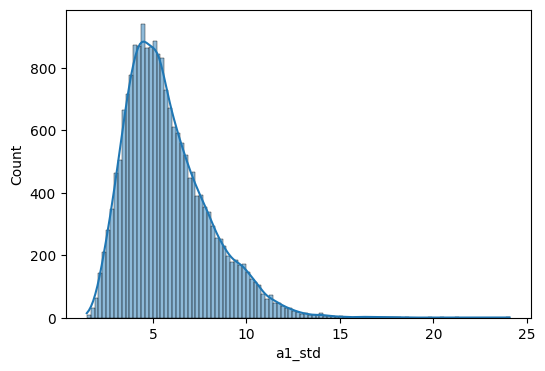

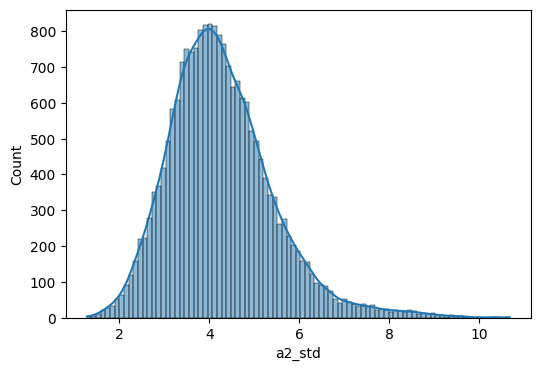

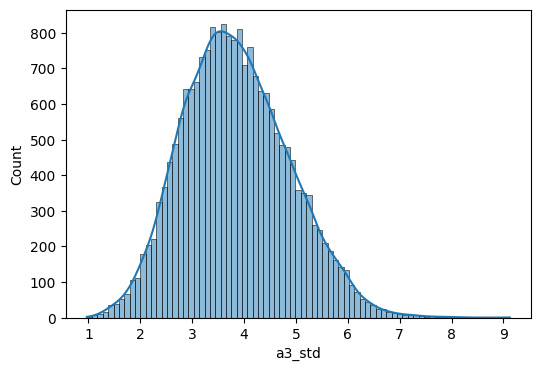

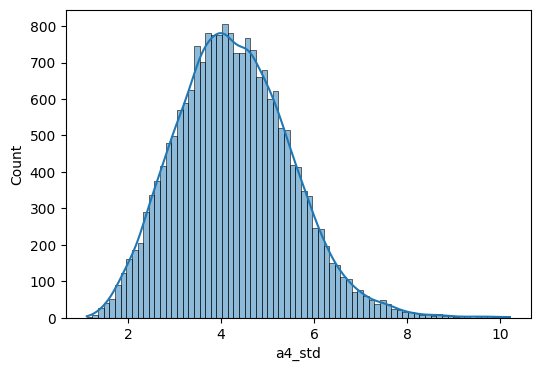

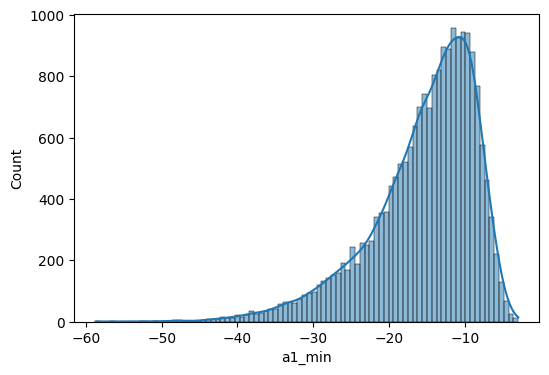

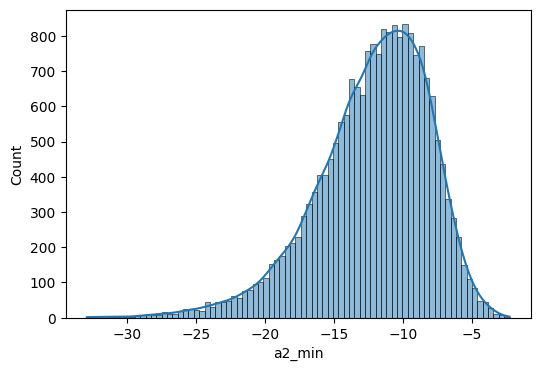

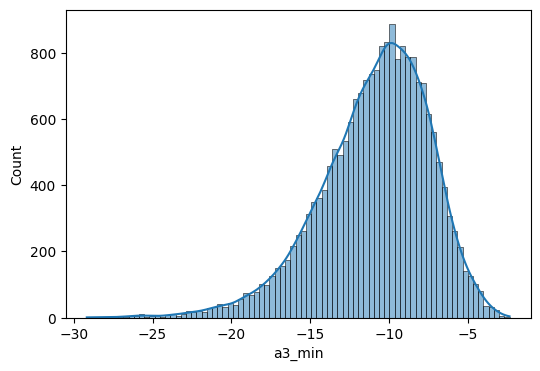

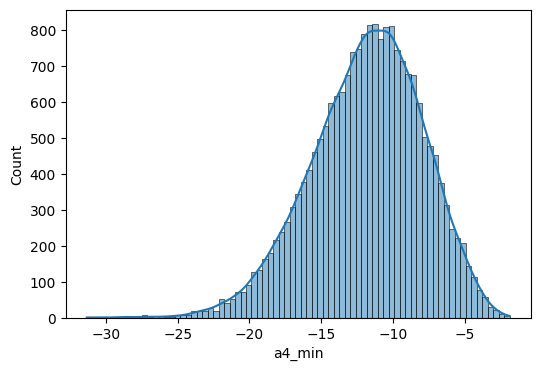

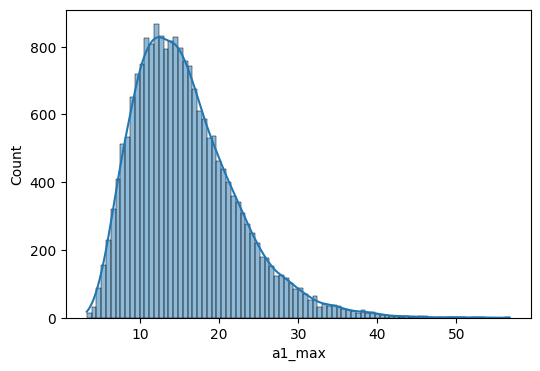

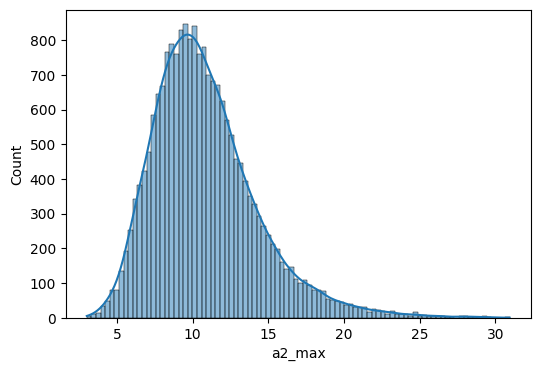

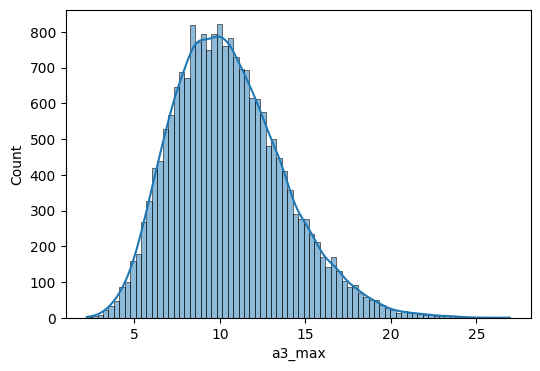

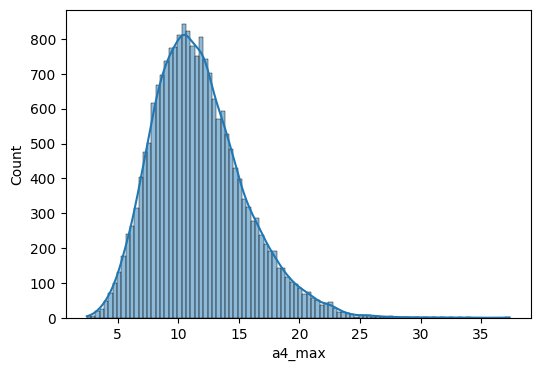

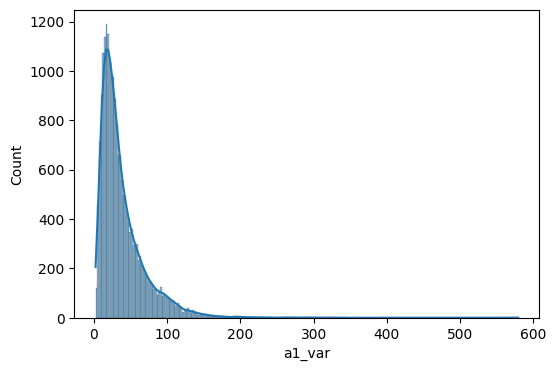

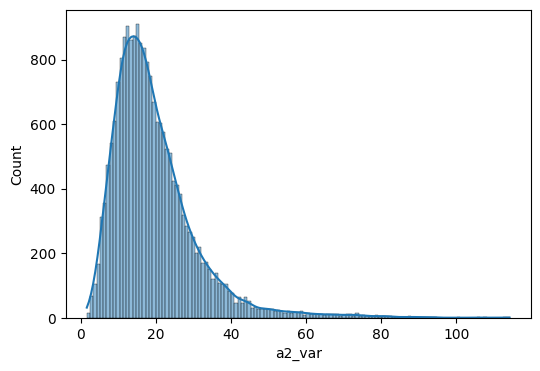

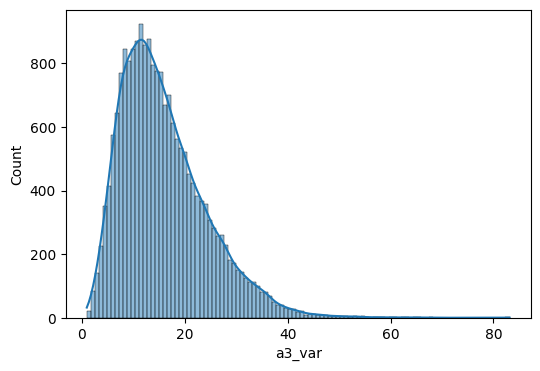

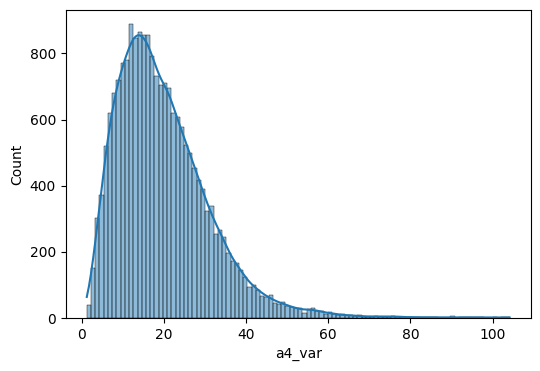

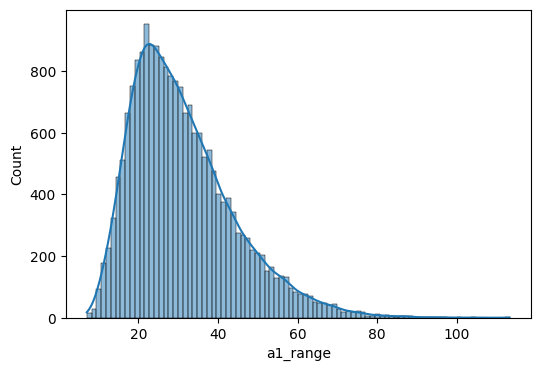

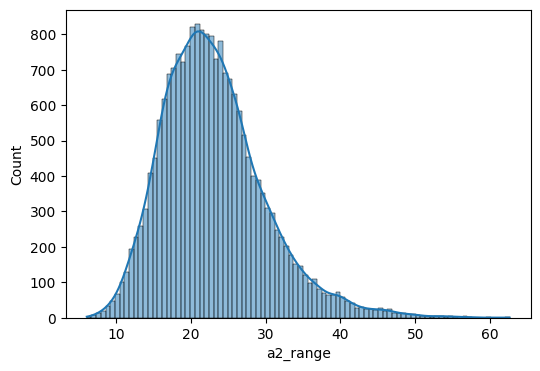

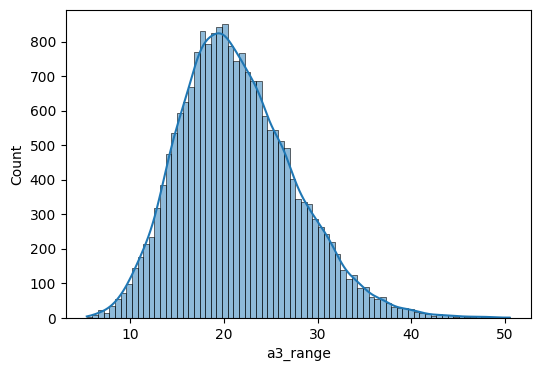

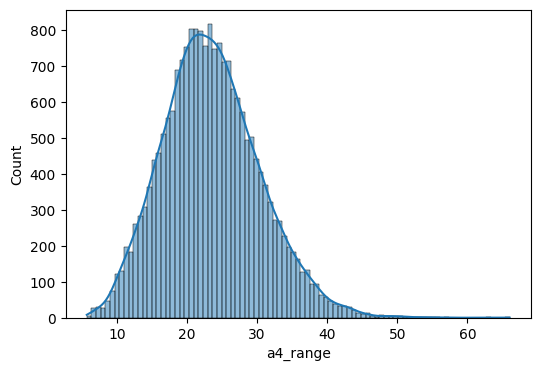

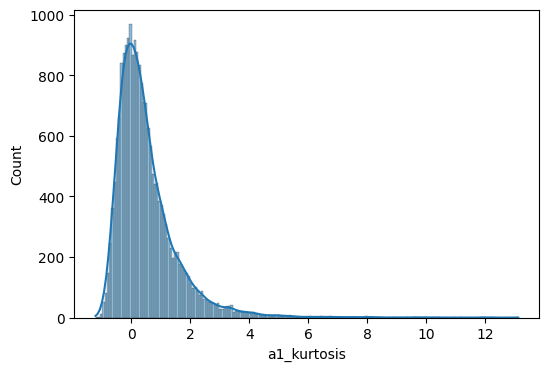

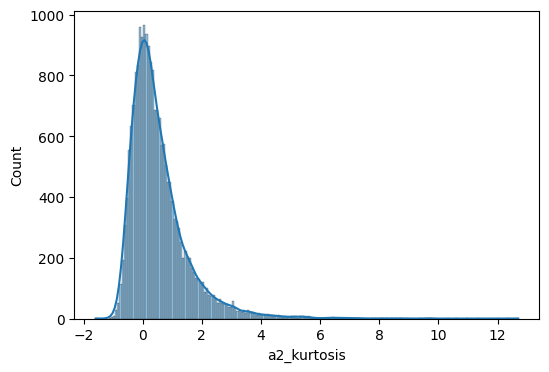

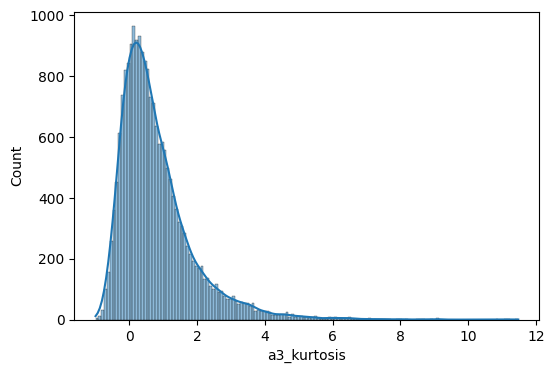

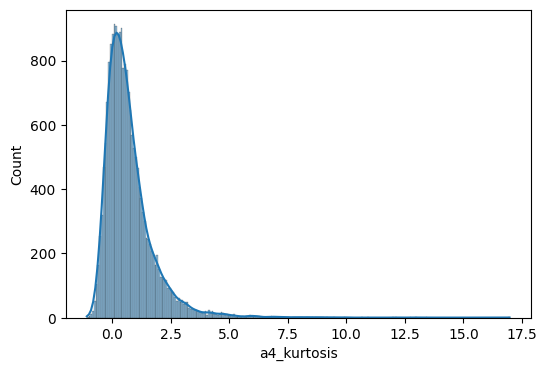

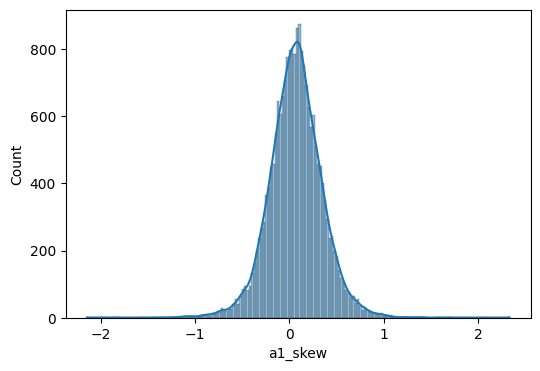

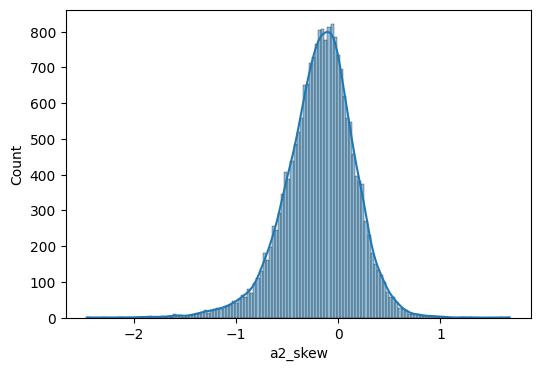

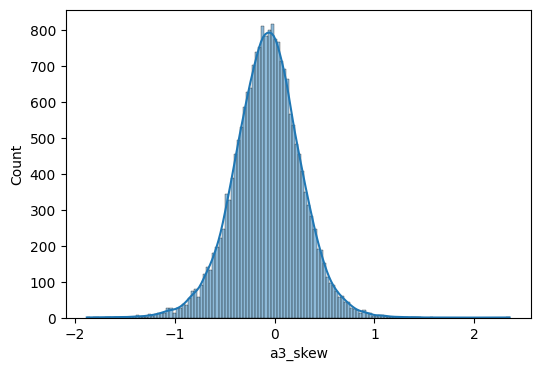

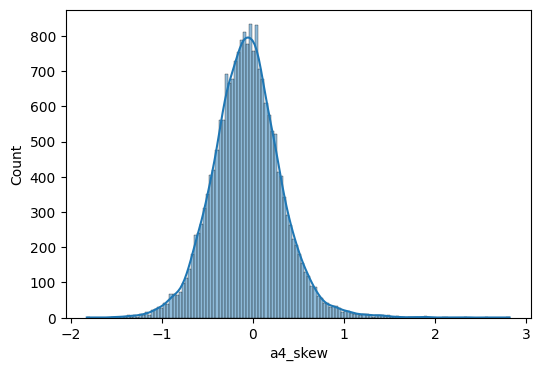

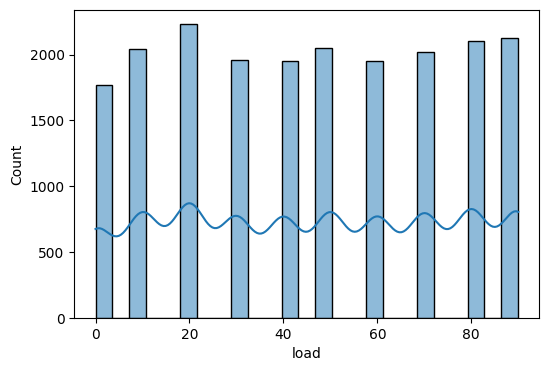

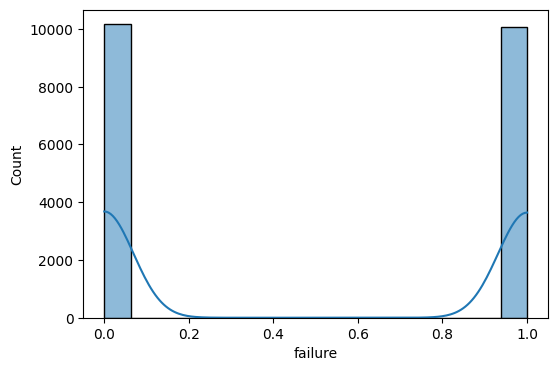

In [72]:
for col in df_final.columns:
    plt.figure(figsize=(6,4))
    sns.histplot(x=df_final[col],kde=True)

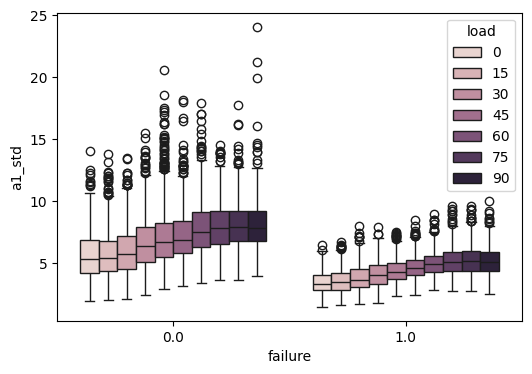

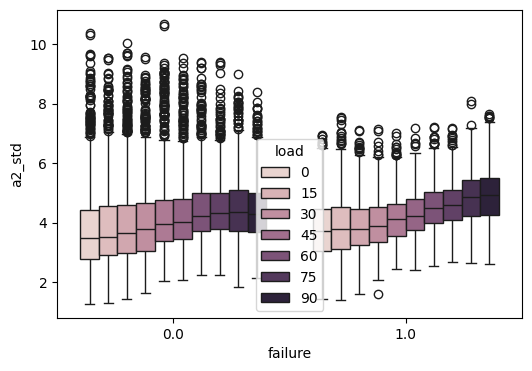

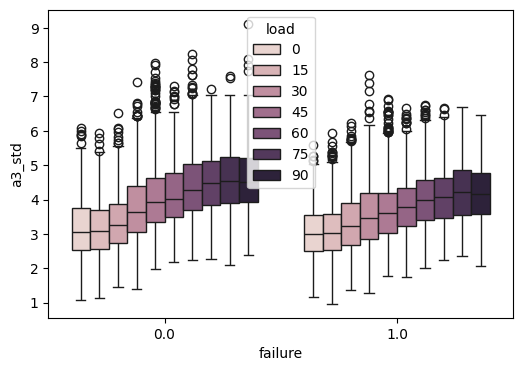

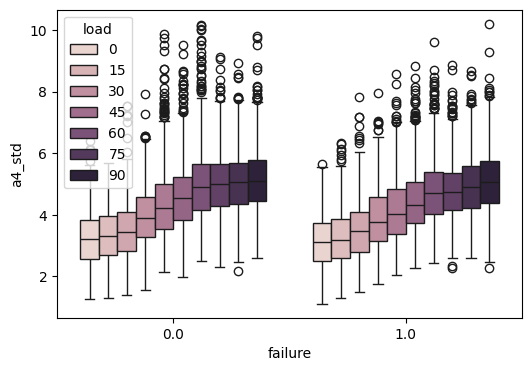

In [73]:
quant_cols=["a1_std","a2_std","a3_std","a4_std"]
for col in quant_cols:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df_final["failure"],y=df_final[col],hue=df_final["load"])

<Axes: xlabel='failure', ylabel='load'>

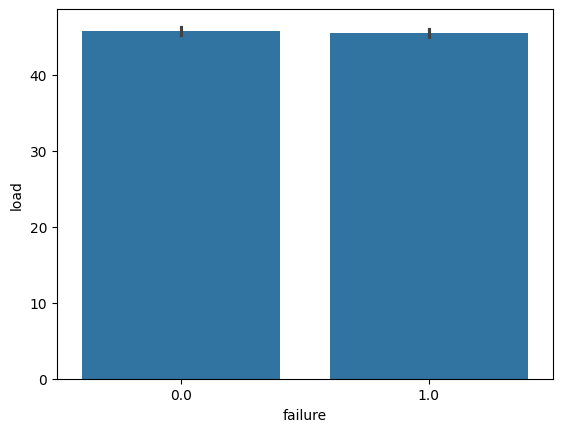

In [74]:
sns.barplot(x=df_final["failure"],y=df_final["load"],estimator=np.mean)

In [75]:
df_final.head()

,a1_std,a2_std,a3_std,a4_std,a1_min,a2_min,a3_min,a4_min,a1_max,a2_max,...,a1_kurtosis,a2_kurtosis,a3_kurtosis,a4_kurtosis,a1_skew,a2_skew,a3_skew,a4_skew,load,failure
0,2.773743,3.625441,3.053217,2.479670,-6.75195,-8.78230,-6.87031,-4.42552,6.94606,7.58304,...,-0.323687,0.004087,0.099096,1.108623,-0.257241,-0.162347,0.124041,0.622273,0.0,1.0
1,3.009118,3.566201,2.854556,2.597574,-6.79768,-8.27673,-6.90384,-7.08858,6.18348,9.62947,...,-0.685575,-0.165116,0.275550,0.387465,-0.276394,0.095039,0.346980,-0.098255,0.0,1.0
2,2.258893,3.189251,1.971267,1.726624,-6.03566,-8.72943,-4.80122,-5.43327,5.48630,7.11868,...,0.022196,0.066009,-0.014646,0.844893,-0.172785,-0.203286,0.119108,-0.233903,0.0,1.0
3,2.486789,2.758437,2.658690,2.068924,-5.98302,-6.96731,-8.49161,-3.86559,4.91734,9.08417,...,-0.335753,0.799129,0.765071,2.535101,-0.197734,-0.073012,-0.001285,0.727516,0.0,1.0
4,3.245092,3.051541,2.536531,2.085758,-9.57229,-11.21170,-7.04513,-4.19897,9.27243,8.73261,...,1.059798,1.290685,0.231211,1.418064,-0.220589,-0.212601,-0.269316,0.947665,0.0,1.0


In [76]:
df_final.columns

Index(['a1_std', 'a2_std', 'a3_std', 'a4_std', 'a1_min', 'a2_min', 'a3_min',
       'a4_min', 'a1_max', 'a2_max', 'a3_max', 'a4_max', 'a1_var', 'a2_var',
       'a3_var', 'a4_var', 'a1_range', 'a2_range', 'a3_range', 'a4_range',
       'a1_kurtosis', 'a2_kurtosis', 'a3_kurtosis', 'a4_kurtosis', 'a1_skew',
       'a2_skew', 'a3_skew', 'a4_skew', 'load', 'failure'],
      dtype='object')

In [77]:
df_final.shape

(20213, 30)

In [78]:
df_final.to_csv("cleaned.csv",index=False)

In [79]:
df["a1"].min()

np.float64(-25.3461)